# 8. So sánh tổng hợp – tự chọn thuật toán tốt nhất

Thử **mọi phương án** của từng quyết định trong hệ thống, chọn phương án tốt nhất theo một quy tắc nêu trước, rồi
(nếu `APPLY = True`) ghi vào cấu hình hệ thống (`BE/apps/algorithms/benchmark.py`):

| Quyết định | Các phương án được thử | Cách đánh giá |
|---|---|---|
| Lịch ôn | Leitner · SM-2 · FSRS · FSRS + GA, retention 0,80 / 0,85 / 0,90 | mô phỏng người học |
| Thứ tự ôn | theo hạn · VIP thuần (4 bộ trọng số) · **VIP lai** (theo hạn, VIP đẩy sớm tối đa 1 / 3 / 7 ngày) | mô phỏng người học |
| Dự đoán nhớ/quên | Leitner · SM-2 · FSRS · FSRS + GA | log-loss, AUC, accuracy trên tập test |
| Đáp án nhiễu | ngẫu nhiên cùng chủ đề · Smart Distractor | độ gần nghĩa, tỉ lệ đáp án nhiễu cũng đúng |
| Tìm điểm gần | PostgreSQL earthdistance · lưới + Haversine | độ chính xác, thời gian |
| Nhận diện ảnh | model tự train · COCO · kết hợp | top-1 trên ảnh từ vựng thật |

**Quy tắc chọn lịch ôn × thứ tự ôn:** trong các tổ hợp có tỉ lệ nhớ chung không thấp hơn tổ hợp tốt nhất quá
`TOLERANCE` (2 điểm %), chọn tổ hợp giữ **từ dễ nhầm qua ảnh** tốt nhất (mục tiêu của VIP). Như vậy VIP chỉ được chọn
khi không làm hại việc học nói chung. Mỗi tổ hợp được mô phỏng trên 3 nhóm người học (lấy trung bình); tổ hợp được
chọn được **kiểm tra lại trên một nhóm người học mới** không dùng khi chọn.

> **Cách chạy:** mở bằng VS Code (hoặc Jupyter), chọn kernel **LingoPrism (BE venv)** rồi *Run All*. PostgreSQL phải đang chạy. Notebook dùng đúng mã nguồn của server (`BE/apps/algorithms`), kết quả được lưu vào database nên trang **Admin → Thuật toán AI** hiện ngay kết quả mới nhất. Mọi biểu đồ được lưu thêm thành ảnh PNG trong `AI/notebooks/figures/` để đưa vào báo cáo.

In [1]:
# Khởi tạo: nạp Django của BE/ (database + mã thuật toán thật của server) và matplotlib
import pathlib, sys
_here = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "AI/notebooks/lingoprism_setup.py").exists())
sys.path.insert(0, str(_here / "AI/notebooks"))
from lingoprism_setup import ROOT, init, save, table
init()

import random, time
import numpy as np
import matplotlib.pyplot as plt

Django OK – config.settings.dev | hình lưu ở D:\kicuoi\doantotnghiep\SnapLingua-main\AI\notebooks\figures


In [2]:
TOLERANCE = 0.02   # chấp nhận giảm tối đa 2 điểm % tỉ lệ nhớ chung
APPLY = True       # ghi cấu hình tốt nhất vào hệ thống

In [3]:
from apps.algorithms import benchmark
from apps.algorithms.models import AlgorithmConfig

run = benchmark.run(apply=APPLY, tolerance=TOLERANCE)
res = run.results
print(f"Xong sau {run.duration_s:.0f}s")

▶ Dự đoán nhớ / quên (tập test)
▶ Lịch ôn × thứ tự ôn (mô phỏng)


  leitner r=0.9: xong


  sm2 r=0.9: xong


  fsrs r=0.8: xong


  fsrs r=0.85: xong


...

  fsrs_ga r=0.8: xong


  fsrs_ga r=0.85: xong


  fsrs_ga r=0.9: xong


▶ Smart Distractor / Proximity


Xong sau 94s


## 8.1 Quyết định

In [4]:
table([{k: d.get(k, "") for k in ("decision", "chosen", "evidence")} for d in res["decisions"]])

decision                                 chosen          evidence                                               
---------------------------------------  --------------  -------------------------------------------------------
Lịch ôn                                  FSRS+GA r=0.9   nhớ chung 47.5%, từ dễ nhầm 36.1% (mô phỏng)           
Thứ tự ôn                                VIP lai 1 ngày  trong ngưỡng −2% nhớ chung, giữ từ dễ nhầm tốt nhất    
Đáp án nhiễu                             smart           độ gần nghĩa 0.4114 → 0.6128, đáp án nhiễu cũng đúng 0%
Tìm điểm gần                             grid            đúng 500/500 so với brute force, 0.0153 ms vs 1.4852 ms
Nhận diện ảnh (lingoprism-yolov10n)      combined        coco top-1 87%, trained top-1 50%, combined top-1 81%  
Nhận diện ảnh (yolov8s-oiv7-lingoprism)  combined        coco top-1 87%, trained top-1 62%, combined top-1 77%  
Nhận diện ảnh (yolov8m-oiv7-lingoprism)  combined        coco top-1 87%, trained top-1 66%, comb

## 8.2 Lịch ôn × thứ tự ôn
Mỗi điểm là một tổ hợp. Góc trên bên phải là tốt nhất; các tổ hợp trên đường Pareto không bị tổ hợp nào vượt ở cả hai chỉ số.

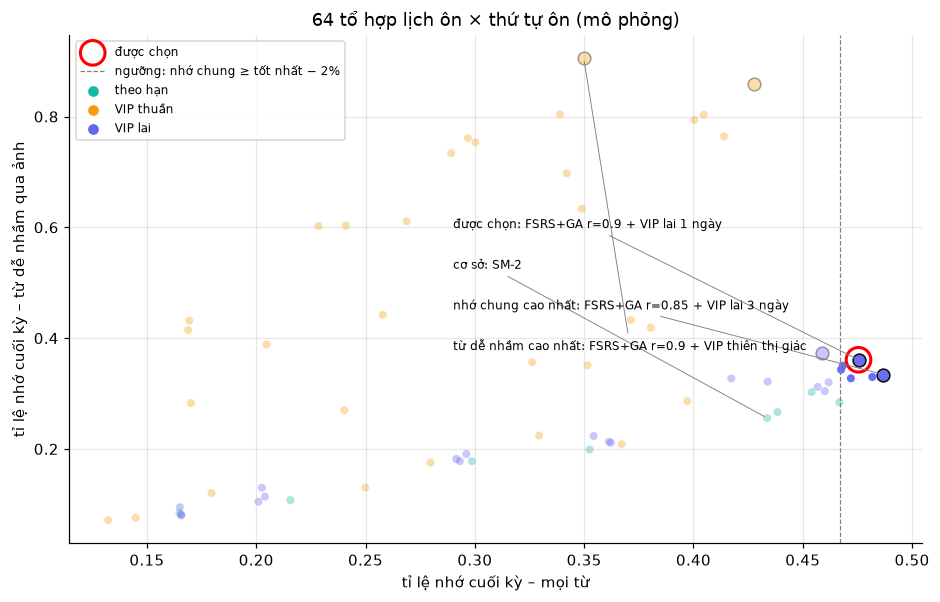

Được chọn: FSRS+GA r=0.9 + VIP lai 1 ngày
tổ hợp                           nhớ chung  từ dễ nhầm  Pareto  trong ngưỡng
-------------------------------  ---------  ----------  ------  ------------
FSRS+GA r=0.85 + VIP lai 3 ngày  0.4868     0.3343      ✓       ✓           
FSRS+GA r=0.85 + VIP lai 1 ngày  0.4818     0.3299              ✓           
FSRS+GA r=0.9 + VIP lai 1 ngày   0.4755     0.3609      ✓       ✓           
FSRS+GA r=0.8 + VIP lai 1 ngày   0.4720     0.3274              ✓           
FSRS+GA r=0.85 + VIP lai 7 ngày  0.4683     0.3501              ✓           
FSRS+GA r=0.9 + VIP lai 3 ngày   0.4675     0.3429              ✓           
FSRS+GA r=0.85                   0.4667     0.2840                          
FSRS+GA r=0.8 + VIP lai 3 ngày   0.4618     0.3203                          
SM-2 + VIP lai 3 ngày            0.4601     0.3043                          
FSRS+GA r=0.9 + VIP lai 7 ngày   0.4586     0.3725      ✓                   
SM-2 + VIP lai 1 ngày            0

In [5]:
rows = res["schedule"]["rows"]
chosen = res["schedule"]["chosen"]
color = lambda r: "#14b8a6" if r["priority"] == "due" else "#6366f1" if r["priority"].startswith("vip_due") else "#f59e0b"
fig, ax = plt.subplots(figsize=(10, 6))
for r in rows:
    ax.scatter(r["recall_all"], r["recall_confusable"], s=70 if r["pareto"] else 28, c=color(r),
               alpha=0.95 if r["eligible"] else 0.35, edgecolors="k" if r["pareto"] else "none")
marks = {"được chọn": chosen, "cơ sở": res["schedule"]["baseline"], "nhớ chung cao nhất": res["schedule"]["best_overall"],
         "từ dễ nhầm cao nhất": max(rows, key=lambda r: r["recall_confusable"])}
for i, (what, r) in enumerate(marks.items()):
    ax.annotate(f"{what}: {benchmark.label(r)}", (r["recall_all"], r["recall_confusable"]), fontsize=8,
                xytext=(0.45, 0.62 - 0.08 * i), textcoords="axes fraction",
                arrowprops={"arrowstyle": "-", "color": "gray", "lw": 0.6})
ax.scatter(chosen["recall_all"], chosen["recall_confusable"], s=260, facecolors="none", edgecolors="red", lw=2, label="được chọn")
best = max(r["recall_all"] for r in rows)
ax.axvline(best - TOLERANCE, ls="--", c="gray", lw=0.8, label=f"ngưỡng: nhớ chung ≥ tốt nhất − {TOLERANCE:.0%}")
for name, c in (("theo hạn", "#14b8a6"), ("VIP thuần", "#f59e0b"), ("VIP lai", "#6366f1")):
    ax.scatter([], [], c=c, label=name)
ax.set_xlabel("tỉ lệ nhớ cuối kỳ – mọi từ")
ax.set_ylabel("tỉ lệ nhớ cuối kỳ – từ dễ nhầm qua ảnh")
ax.set_title(f"{len(rows)} tổ hợp lịch ôn × thứ tự ôn (mô phỏng)")
ax.legend(fontsize=8)
save(fig, "08_to_hop_pareto")
plt.show()
print("Được chọn:", benchmark.label(chosen))
table([{"tổ hợp": benchmark.label(r), "nhớ chung": r["recall_all"], "từ dễ nhầm": r["recall_confusable"],
        "Pareto": "✓" if r["pareto"] else "", "trong ngưỡng": "✓" if r["eligible"] else ""}
       for r in sorted(rows, key=lambda r: -r["recall_all"])[:12]])

## 8.3 Kiểm tra lại trên nhóm người học mới

label                            recall_all  recall_confusable
-------------------------------  ----------  -----------------
SM-2                             0.4363      0.2638           
FSRS+GA r=0.85 + VIP lai 3 ngày  0.4345      0.2756           
FSRS+GA r=0.9 + VIP lai 1 ngày   0.4687      0.3273           


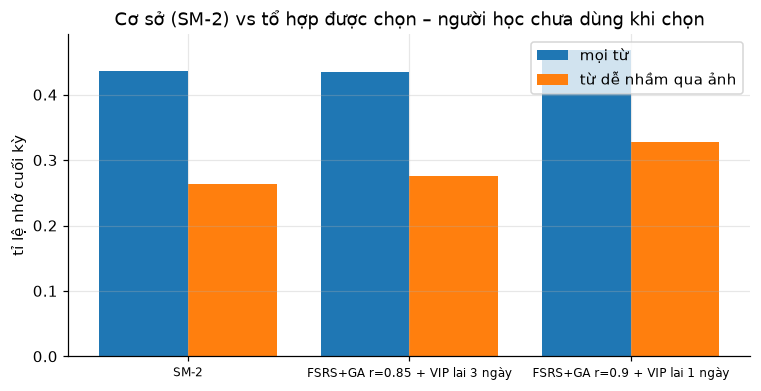

In [6]:
val = res["schedule"]["validation"]
table(val)
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(val))
ax.bar(x - 0.2, [v["recall_all"] for v in val], 0.4, label="mọi từ")
ax.bar(x + 0.2, [v["recall_confusable"] for v in val], 0.4, label="từ dễ nhầm qua ảnh")
ax.set_xticks(x, [v["label"] for v in val], fontsize=8)
ax.set_ylabel("tỉ lệ nhớ cuối kỳ")
ax.set_title("Cơ sở (SM-2) vs tổ hợp được chọn – người học chưa dùng khi chọn")
ax.legend()
save(fig, "08_kiem_tra_lai")
plt.show()

## 8.4 Dự đoán nhớ / quên (tập test)

In [7]:
pm = res["prediction"]["models"]
names = {"leitner": "Leitner", "sm2": "SM-2", "fsrs": "FSRS", "fsrs_ga": "FSRS + GA"}
table([{"mô hình": names[k], **{m: v[m] for m in ("log_loss", "auc", "accuracy", "recall_rate")}} for k, v in pm.items()])
print("Lưu ý: luôn đoán 'nhớ' đã được accuracy =", pm["sm2"]["recall_rate"], "→ dùng AUC / log-loss làm thước đo chính.")

mô hình    log_loss  auc     accuracy  recall_rate
---------  --------  ------  --------  -----------
Leitner    0.6783    0.6827  0.6813    0.6642     
SM-2       0.6319    0.6357  0.6881    0.6642     
FSRS       0.7086    0.6909  0.6758    0.6642     
FSRS + GA  0.5210    0.7713  0.7688    0.6642     
Lưu ý: luôn đoán 'nhớ' đã được accuracy = 0.6642 → dùng AUC / log-loss làm thước đo chính.


## 8.5 Cấu hình hệ thống sau khi chạy

In [8]:
cfg = AlgorithmConfig.get()
for k in ("scheduler", "desired_retention", "review_priority", "vip_weights", "distractor", "proximity"):
    print(f"{k:18s} {getattr(cfg, k)}")
print("FSRS dùng tham số GA:", len(cfg.fsrs_weights or []) == 17)

scheduler          fsrs
desired_retention  0.9
review_priority    vip
vip_weights        {'forget': 0.4, 'due_days': 1, 'confusion': 0.2, 'confidence': 0.15, 'difficulty': 0.25}
distractor         smart
proximity          grid
FSRS dùng tham số GA: True
